# Daily actual versus predicted streamflow

Choose a gage, **one or more models**, year, and month in the next cell, then run both code cells. The chart shows one point per **target date**: observed daily mean discharge and each model's next-day forecast. The `persistence` model is the previous day's observed flow. The legend reports each model's mean absolute error (MAE) for the selected month.

This notebook reads `data/models/predictions.csv` generated by `train_models.py`. It works when launched from either the project root or this folder. If Matplotlib is missing from the selected notebook kernel, install the notebook requirements described in the README.

In [11]:
from pathlib import Path

# Edit these four values, then rerun this cell and the plot cell.
SITE_NUMBER = "08062700"  # Rosser: 08062500; Trinidad: 08062700; Goodrich: 08066250
MODELS = ["linear_regression", "persistence", "lstm"]
# Choices: persistence, linear_regression, gradient_boosting, random_forest, svr, lstm
# For one model, use a one-item list such as ["lstm"].
YEAR = 2023
MONTH = 3

# Set an explicit Path here if the CSV is stored somewhere else.
PREDICTIONS_CSV = next(
    (path for path in (
        Path("data/models/predictions.csv"),
        Path("trinity_pipeline/data/models/predictions.csv"),
    ) if path.is_file()),
    None,
)
if PREDICTIONS_CSV is None:
    raise FileNotFoundError("Could not find predictions.csv. Run train_models.py first, or set PREDICTIONS_CSV to its path.")
print(f"Reading {PREDICTIONS_CSV.resolve()}")

Reading /home/zack/Documents/DTSC5505Project/trinity_pipeline/data/models/predictions.csv


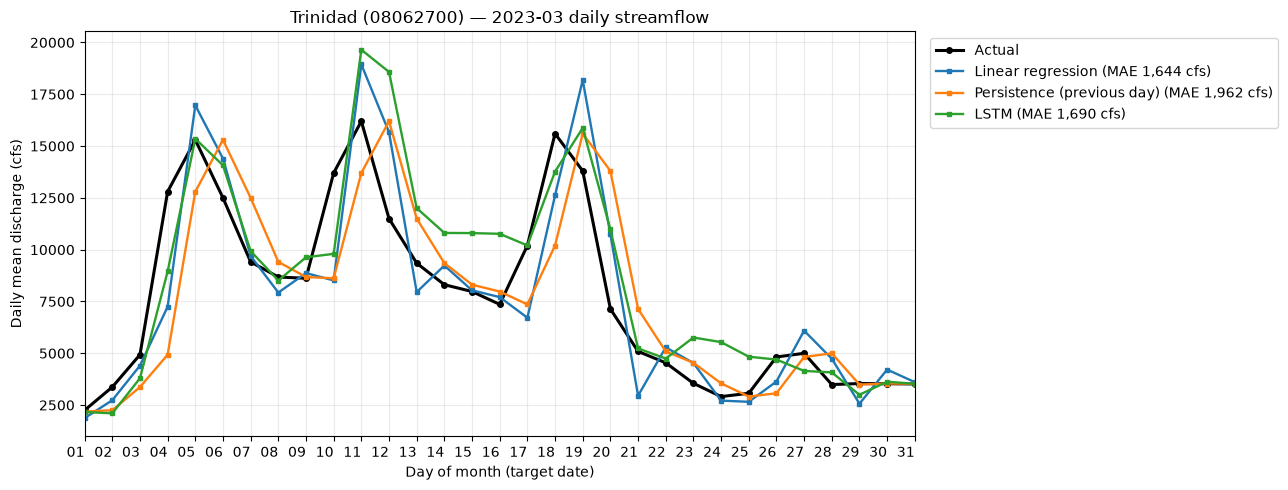

In [12]:
import csv
import calendar
from datetime import date
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SITE_NAMES = {"08062500": "Rosser", "08062700": "Trinidad", "08066250": "Goodrich"}
MODEL_NAMES = {
    "persistence": "Persistence (previous day)",
    "linear_regression": "Linear regression",
    "gradient_boosting": "Gradient boosting",
    "random_forest": "Random forest",
    "svr": "SVR",
    "lstm": "LSTM",
}
if SITE_NUMBER not in SITE_NAMES:
    raise ValueError(f"Unknown gage {SITE_NUMBER!r}. Choose one of {list(SITE_NAMES)}.")
if isinstance(MODELS, str):
    MODELS = [MODELS]
if not MODELS or len(MODELS) != len(set(MODELS)):
    raise ValueError("MODELS must contain one or more distinct model names.")
unknown = [model for model in MODELS if model not in MODEL_NAMES]
if unknown:
    raise ValueError(f"Unknown model(s): {unknown}. Choose from {list(MODEL_NAMES)}.")
if not 1 <= MONTH <= 12:
    raise ValueError("MONTH must be 1 through 12.")

actual_by_day = {}
predictions_by_model = {model: {} for model in MODELS}
with PREDICTIONS_CSV.open(newline="", encoding="utf-8") as stream:
    for row in csv.DictReader(stream):
        model = row["model"]
        if row["site_number"] != SITE_NUMBER or model not in predictions_by_model:
            continue
        target_day = date.fromisoformat(row["target_date"])
        if target_day.year != YEAR or target_day.month != MONTH:
            continue
        actual = float(row["actual_cfs"])
        if target_day in actual_by_day and actual_by_day[target_day] != actual:
            raise ValueError(f"Conflicting actual flow on {target_day}; inspect predictions.csv.")
        if target_day in predictions_by_model[model]:
            raise ValueError(f"Duplicate {model} prediction on {target_day}; inspect predictions.csv.")
        actual_by_day[target_day] = actual
        predictions_by_model[model][target_day] = float(row["predicted_cfs"])

missing_models = [model for model, values in predictions_by_model.items() if not values]
if missing_models:
    raise ValueError(f"No predictions for {missing_models} at {SITE_NAMES[SITE_NUMBER]} in {YEAR}-{MONTH:02d}. "
                     "Choose a month in the validation or test period shown in split_dates.json.")

# Use every calendar day on the x-axis. Missing observations remain gaps.
days = [date(YEAR, MONTH, day) for day in range(1, calendar.monthrange(YEAR, MONTH)[1] + 1)]
actual_values = [actual_by_day.get(day, float("nan")) for day in days]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(days, actual_values, color="black", marker="o", markersize=4,
        linewidth=2.2, label="Actual")
for model in MODELS:
    values = predictions_by_model[model]
    predicted_values = [values.get(day, float("nan")) for day in days]
    mae = sum(abs(actual_by_day[day] - prediction) for day, prediction in values.items()) / len(values)
    ax.plot(days, predicted_values, marker="s", markersize=3, linewidth=1.7,
            label=f"{MODEL_NAMES[model]} (MAE {mae:,.0f} cfs)")

ax.set_title(f"{SITE_NAMES[SITE_NUMBER]} ({SITE_NUMBER}) — {YEAR}-{MONTH:02d} daily streamflow")
ax.set_xlabel("Day of month (target date)")
ax.set_ylabel("Daily mean discharge (cfs)")
ax.set_xticks(days)
ax.set_xlim(days[0], days[-1])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
ax.grid(True, alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.autofmt_xdate(rotation=0)
fig.tight_layout()
plt.show()